# 02 · Report labelling: from free text to soft training labels

Three kinds of label source are combined per finding:

1. **Rule-based multilingual labeler** (`kneemri.labels.keyword`): regex patterns with negation handling in about ten languages.
2. **LLM grading** (`kneemri.labels.llm`): Qwen2.5-14B-Instruct (4-bit) grades every report 0–3 per finding as JSON;
   the token probabilities of the grade digits give a continuous *expected grade*. A second LLM pass used a stricter
   written grading rubric with a 0–4 scale.
3. **Teacher**: predictions of earlier image models on every training study (distillation).

Each source is scored against the 58 gold studies, and sources are blended per finding with weight `(AUC − 0.5)²`.

The LLM passes need a GPU and run on Kaggle (`ReportGrader(...).grade(reports)`); this notebook loads their saved outputs.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kneemri.constants import LABELS
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MET = ROOT / "reports" / "metrics"; MET.mkdir(parents=True, exist_ok=True)

In [2]:
from kneemri.labels.keyword import label_report, to_soft
from kneemri.labels.blend import calibrate_grades, grades_to_labels, source_quality, blend_sources

train = pd.read_csv(ROOT / "data" / "train.csv")
gold = train[train[LABELS].notna().all(axis=1)][["StudyInstanceUID"] + LABELS].reset_index(drop=True)
LBL = ROOT / "data" / "labels"

## 1. Rule-based labels

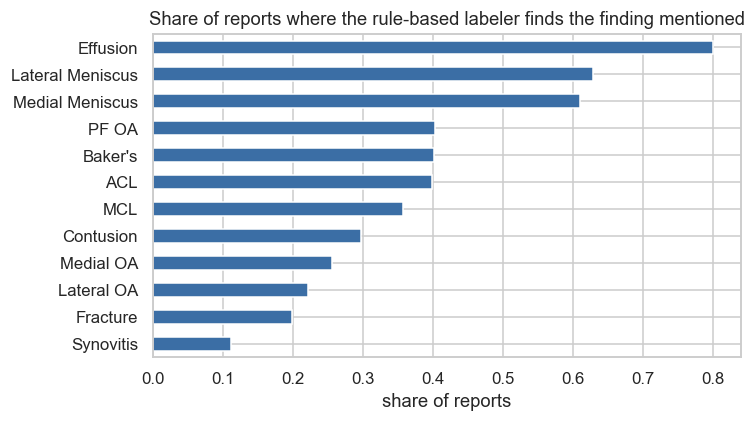

In [3]:
kw_hard = pd.DataFrame([label_report(t) for t in train.Report.fillna("")])
keyword = kw_hard.apply(lambda col: col.map(to_soft)).astype(float)
keyword.insert(0, "StudyInstanceUID", train.StudyInstanceUID.values)
mention = kw_hard.notna().mean().sort_values()
ax = mention.plot.barh(figsize=(7, 4), color="#3b6ea5", title="Share of reports where the rule-based labeler finds the finding mentioned")
ax.set_xlabel("share of reports"); plt.tight_layout(); plt.show()

## 2. LLM grades → calibrated probabilities
Grades are mapped to probabilities with the gold studies: P(finding | grade), smoothed with a Beta prior and forced
to increase with the grade. The expected grade is interpolated on that curve.

In [4]:
grades = pd.read_csv(LBL / "09_report_llm_grades_v2.csv")
calib = calibrate_grades(grades, gold)
llm = grades_to_labels(grades, calib)
pd.DataFrame(calib).T.round(2).rename(columns=lambda k: f"P(y | grade {k})")

,P(y | grade 0),P(y | grade 1),P(y | grade 2),P(y | grade 3)
ACL,0.04,0.15,0.59,1.00
MCL,0.00,0.19,0.79,0.97
Medial Meniscus,0.05,0.11,0.83,0.83
Lateral Meniscus,0.11,0.63,0.79,0.99
Medial OA,0.00,0.45,0.92,0.98
Lateral OA,0.05,0.53,0.57,0.78
PF OA,0.16,0.41,0.92,0.95
Effusion,0.01,0.64,0.94,0.98
Synovitis,0.23,0.76,0.76,0.95
Baker's,0.06,0.68,0.90,0.95


In [5]:
hard_vs_exp = pd.DataFrame({
    "hard grade": source_quality({"h": grades.rename(columns={f"{c}__hard": c for c in LABELS})[["StudyInstanceUID"] + LABELS].fillna(0)}, gold)["h"],
    "expected grade": source_quality({"e": llm}, gold)["e"]})
print(hard_vs_exp.mean().round(3).to_string())
print("Expected grades break ties between reports with the same hard grade, which lifts ranking quality (AUC).")

hard grade        0.833
expected grade    0.884
Expected grades break ties between reports with the same hard grade, which lifts ranking quality (AUC).


## 3. Every source against gold

In [6]:
sources = {
    "Rule-based": keyword,
    "LLM (Qwen2.5-14B)": llm,
    "LLM rubric pass": pd.read_csv(LBL / "llm_rubric_report_labels.csv"),
    "Teacher (image models)": pd.read_csv(LBL / "10_report_labels.csv"),
}
blended, weights = blend_sources(sources, gold, fallback=keyword)
quality = source_quality({**sources, "Blend": blended}, gold)
quality.loc["macro"] = quality.mean()
quality.round(3)

,Rule-based,LLM (Qwen2.5-14B),LLM rubric pass,Teacher (image models),Blend
ACL,0.908,0.987,0.986,0.934,0.990
MCL,0.828,0.982,0.981,0.948,0.982
Medial Meniscus,0.841,0.905,0.931,0.963,0.962
Lateral Meniscus,0.776,0.868,0.876,0.888,0.912
Medial OA,0.653,0.944,0.937,0.978,0.984
Lateral OA,0.471,0.878,0.834,0.787,0.880
PF OA,0.562,0.821,0.898,0.802,0.894
Effusion,0.624,0.804,0.812,0.865,0.911
Synovitis,0.639,0.798,0.795,0.645,0.823
Baker's,0.851,0.888,0.943,0.947,0.951


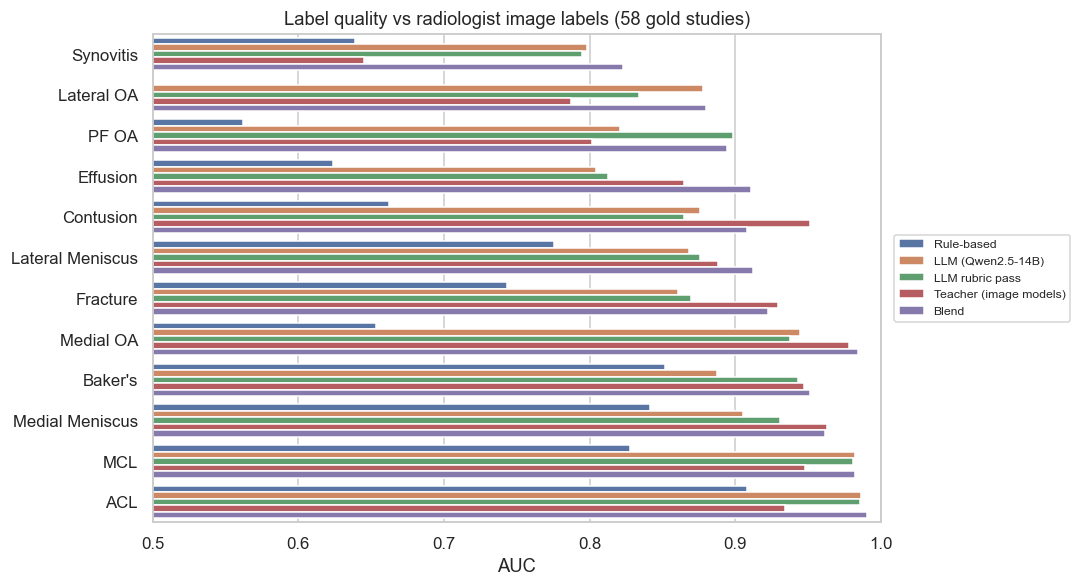

,Rule-based,LLM (Qwen2.5-14B),LLM rubric pass,Teacher (image models),Blend
macro,0.713,0.884,0.894,0.886,0.927


In [7]:
order = quality.drop("macro").mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
q = quality.loc[order].reset_index(names="finding").melt(id_vars="finding", var_name="source", value_name="AUC")
sns.barplot(data=q, y="finding", x="AUC", hue="source", ax=ax, palette="deep")
ax.set(xlim=(0.5, 1.0), title="Label quality vs radiologist image labels (58 gold studies)", ylabel="")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "02_label_quality.png"); plt.show()
quality.loc[["macro"]].round(3)

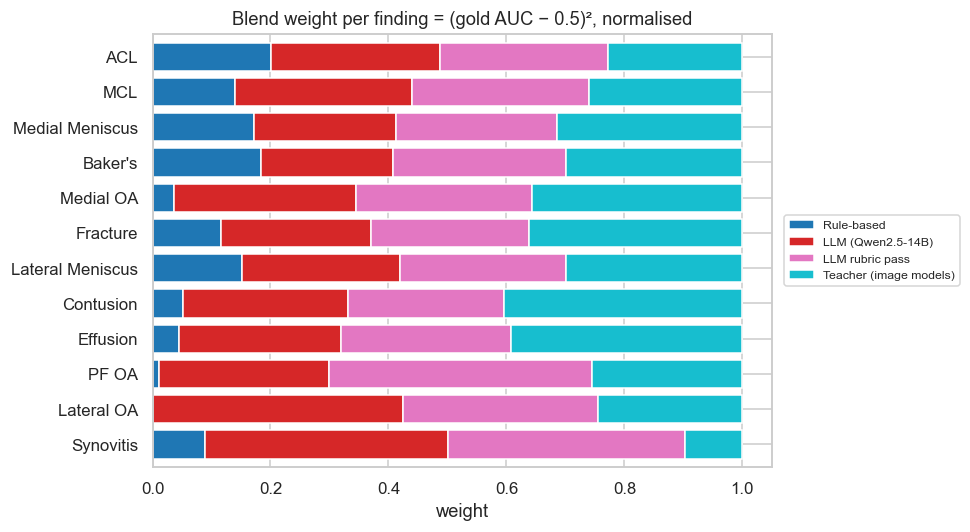

In [8]:
ax = weights.loc[order].plot.barh(stacked=True, figsize=(9, 5), colormap="tab10", width=0.8)
ax.set(title="Blend weight per finding = (gold AUC − 0.5)², normalised", xlabel="weight", ylabel="")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8); plt.tight_layout(); plt.savefig(FIG / "02_blend_weights.png"); plt.show()

In [9]:
out = ROOT / "outputs" / "labels"; out.mkdir(parents=True, exist_ok=True)
blended.to_csv(out / "blended_labels.csv", index=False)
quality.round(4).to_csv(MET / "label_quality_vs_gold.csv")
print("training labels:", blended.shape, "->", out / "blended_labels.csv")

training labels: (4407, 13) -> D:\M.TECH\SEM-3\knee-mri-abnormality-detection\outputs\labels\blended_labels.csv


**Takeaways**
* Rule-based labels are weak (they miss hedged and implied findings); LLM grading lifts label quality the most.
* Weakest findings: synovitis, effusion and PF OA. Radiologists reading images flag these more often than reports mention them,
  so every report-derived source is capped there.
* The gold blend score is optimistic, since gold also chose the weights; the leaderboard is the unbiased check.